In [2]:

import torch
from torch import nn

from pathlib import Path
import mininn as mini
from mininn import AdamW

from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

from copy import copy
import time

data_root = "../data_1"
batch_size = 64

In [3]:
# Original training dataset: no random augmentation
train_dataset = datasets.CIFAR10(
    root=data_root,
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Fixed train/validation split
train_subset, val_subset = random_split(
    train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Separate dataset object so augmentation doesn't affect validation
augmented_dataset = copy(train_dataset)
augmented_dataset.transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

augmented_train_subset = Subset(
    augmented_dataset,
    train_subset.indices
)

# Separate test split: no random augmentation
test_dataset = datasets.CIFAR10(
    root=data_root,
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

# Use this loader for parameter updates
augmented_train_loader = DataLoader(
    augmented_train_subset,
    batch_size=batch_size,
    shuffle=True
)

# Use these loaders for evaluation
train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=False
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print(f"Training:   {len(train_subset):,}")
print(f"Validation: {len(val_subset):,}")
print(f"Test:       {len(test_dataset):,}")

Training:   45,000
Validation: 5,000
Test:       10,000


In [4]:
layer = nn.Conv2d(
    in_channels=3,
    out_channels=16,
    kernel_size=3,
    padding=1
)

print(layer.weight.shape)
print(layer.bias.shape)

torch.Size([16, 3, 3, 3])
torch.Size([16])


In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.conv = nn.Conv2d(3,16,kernel_size=3,padding=1)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        return self.relu(self.conv(x))

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SmallCNN().to(device)

x = torch.randn(2, 3, 32, 32, device=device)

print("Output:", model(x).shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Output: torch.Size([2, 16, 32, 32])
Parameters: 448


In [18]:
class TorchResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels=None, stride=1):
        super().__init__()
        
        if out_channels is None:
            out_channels = in_channels
        
        self.branch = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3,stride=stride, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
        )
        
        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels,1, stride=stride
            )
        else:
            self.shortcut = nn.Identity()
    
    def forward(self, x):
        return self.branch(x) + self.shortcut(x)

In [ ]:
block = TorchResidualBlock(16, 32, stride=2).to(device)
x = torch.randn(2, 16, 32, 32, device=device)

print(block(x).shape)

torch.Size([2, 32, 16, 16])


In [ ]:
class ProjectedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            TorchResidualBlock(16,16),
            TorchResidualBlock(16, 32, stride=2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(8192, 10),
        )
        
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [10]:
model_torch = ProjectedCNN().to(device)
model_torch.eval()

with torch.no_grad():
    x = torch.randn(2, 3, 32, 32, device=device)
    print(model_torch(x).shape)

torch.Size([2, 10])


In [11]:
print("MiniNN model available:", "model_projected" in globals())

MiniNN model available: False


In [12]:
checkpoint_path = Path("best_projected_cnn.pt")
print("Checkpoint path:", checkpoint_path.resolve())
print("Exists:", checkpoint_path.exists())

Checkpoint path: /home/devansh/main/machine_learning/deep-learning-lab/DeepVisionLab/best_projected_cnn.pt
Exists: True


In [13]:
model_projected = mini.Sequential([
    mini.Conv2D(3, 16, 3, padding=1, device=device),
    mini.BatchNorm2D(16, device=device),
    mini.ReLU(),

    mini.ResidualBlock(16, device=device),
    mini.ResidualBlock(16, 32, stride=2, device=device),

    mini.Flatten(),
    mini.Linear(8192, 10, device=device),
])

saved_epoch = mini.load_checkpoint(
    checkpoint_path,
    model_projected,
    device=device
)

model_projected.eval()
print("Loaded epoch:", saved_epoch)

Loaded epoch: 10


In [14]:
def copy_conv(source, target):
    target.weight.copy_(source.weight)
    target.bias.copy_(source.bias)


def copy_bn(source, target):
    target.weight.copy_(source.gamma.reshape(-1))
    target.bias.copy_(source.beta.reshape(-1))
    target.running_mean.copy_(source.running_mean.reshape(-1))
    target.running_var.copy_(source.running_var.reshape(-1))


def copy_block(source, target):
    copy_conv(source.branch.layers[0], target.branch[0])
    copy_bn(source.branch.layers[1], target.branch[1])
    copy_conv(source.branch.layers[3], target.branch[3])
    copy_bn(source.branch.layers[4], target.branch[4])

    if source.shortcut is not None:
        copy_conv(source.shortcut, target.shortcut)


with torch.no_grad():
    # Initial convolution and BatchNorm
    copy_conv(model_projected.layers[0], model_torch.features[0])
    copy_bn(model_projected.layers[1], model_torch.features[1])

    # Identity and projection residual blocks
    copy_block(model_projected.layers[3], model_torch.features[3])
    copy_block(model_projected.layers[4], model_torch.features[4])

    # Linear weights use opposite dimension orders
    model_torch.classifier[1].weight.copy_(
        model_projected.layers[6].weight.T
    )
    model_torch.classifier[1].bias.copy_(
        model_projected.layers[6].bias
    )

In [15]:
model_projected.eval()
model_torch.eval()

x_check = torch.randn(2, 3, 32, 32, device=device)

with torch.no_grad():
    mini_logits = model_projected(x_check).clone()
    torch_logits = model_torch(x_check)

print("Max absolute difference:",
      (mini_logits - torch_logits).abs().max().item())

print("Predicted classes match:", torch.equal(
    mini_logits.argmax(dim=1),
    torch_logits.argmax(dim=1)
))

Max absolute difference: 2.193450927734375e-05
Predicted classes match: True


In [17]:
import copy

# Our custom layers cache outputs that may be non-leaf tensors.
# Clear those temporary caches before deepcopy.
def clear_mininn_outputs(layer):
    if hasattr(layer, "out"):
        layer.out = None

    if hasattr(layer, "layers"):
        for child in layer.layers:
            clear_mininn_outputs(child)

    if hasattr(layer, "branch"):
        clear_mininn_outputs(layer.branch)

    if getattr(layer, "shortcut", None) is not None:
        clear_mininn_outputs(layer.shortcut)


clear_mininn_outputs(model_projected)

bench_mini = copy.deepcopy(model_projected)
bench_torch = copy.deepcopy(model_torch)

bench_mini.train()
bench_torch.train()

opt_mini = mini.Adam(bench_mini.parameters(), learning_rate=0.001)
opt_torch = torch.optim.Adam(bench_torch.parameters(), lr=0.001)

images = torch.randn(64, 3, 32, 32, device=device)
labels = torch.randint(0, 10, (64,), device=device)


def mini_step():
    opt_mini.zero_grad()
    loss = torch.nn.functional.cross_entropy(bench_mini(images), labels)
    loss.backward()
    opt_mini.step()


def torch_step():
    opt_torch.zero_grad(set_to_none=True)
    loss = torch.nn.functional.cross_entropy(bench_torch(images), labels)
    loss.backward()
    opt_torch.step()


def benchmark_step(step, warmup=10, repeats=50):
    for _ in range(warmup):
        step()

    if images.is_cuda:
        torch.cuda.synchronize(images.device)

    start = time.perf_counter()

    for _ in range(repeats):
        step()

    if images.is_cuda:
        torch.cuda.synchronize(images.device)

    return 1000 * (time.perf_counter() - start) / repeats


mini_ms = benchmark_step(mini_step)
torch_ms = benchmark_step(torch_step)

print(f"MiniNN:  {mini_ms:.3f} ms per training step")
print(f"PyTorch: {torch_ms:.3f} ms per training step")
print(f"Time ratio: {mini_ms / torch_ms:.2f}x")

MiniNN:  15.944 ms per training step
PyTorch: 2.572 ms per training step
Time ratio: 6.20x


In [18]:
import copy
import torch

from mininn.training import train_one_epoch, evaluate

model_native = ProjectedCNN().to(device)
optimizer_native = torch.optim.Adam(
    model_native.parameters(), lr=0.001
)

best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(1, 11):
    train_loss = train_one_epoch(
        model_native,
        augmented_train_loader,
        optimizer_native,
        device,
    )

    val_metrics = evaluate(model_native, val_loader, device)

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(model_native.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

model_native.load_state_dict(best_state)

train_metrics = evaluate(model_native, train_loader, device)
val_metrics = evaluate(model_native, val_loader, device)

print(f"\nRestored epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

Epoch 1 | Train loss: 1.4045 | Val loss: 1.2076 | Val accuracy: 57.82%
Epoch 2 | Train loss: 1.0548 | Val loss: 1.1901 | Val accuracy: 58.96%
Epoch 3 | Train loss: 0.9475 | Val loss: 1.1326 | Val accuracy: 63.12%
Epoch 4 | Train loss: 0.8953 | Val loss: 1.1821 | Val accuracy: 62.52%
Epoch 5 | Train loss: 0.8522 | Val loss: 1.1162 | Val accuracy: 63.82%
Epoch 6 | Train loss: 0.8081 | Val loss: 1.0618 | Val accuracy: 64.78%
Epoch 7 | Train loss: 0.7780 | Val loss: 0.9942 | Val accuracy: 65.90%
Epoch 8 | Train loss: 0.7484 | Val loss: 1.0093 | Val accuracy: 66.84%
Epoch 9 | Train loss: 0.7155 | Val loss: 0.9926 | Val accuracy: 66.72%
Epoch 10 | Train loss: 0.6974 | Val loss: 0.9761 | Val accuracy: 68.62%

Restored epoch: 10
Training accuracy: 77.07%
Validation accuracy: 68.62%


In [19]:
torch.manual_seed(42)

model_native = ProjectedCNN().to(device)
optimizer_native = torch.optim.Adam(
    model_native.parameters(), lr=0.001
)

In [20]:
best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(1, 21):
    
    if epoch == 11:
        for group in optimizer_native.param_groups:
            group["lr"] = 0.0001
    
    train_loss = train_one_epoch(
        model_native,
        augmented_train_loader,
        optimizer_native,
        device,
    )

    val_metrics = evaluate(model_native, val_loader, device)

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(model_native.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

model_native.load_state_dict(best_state)

train_metrics = evaluate(model_native, train_loader, device)
val_metrics = evaluate(model_native, val_loader, device)

print(f"\nRestored epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

Epoch 1 | Train loss: 1.4024 | Val loss: 1.3381 | Val accuracy: 55.24%
Epoch 2 | Train loss: 1.0492 | Val loss: 1.0544 | Val accuracy: 63.82%
Epoch 3 | Train loss: 0.9579 | Val loss: 1.0917 | Val accuracy: 63.46%
Epoch 4 | Train loss: 0.8982 | Val loss: 1.0478 | Val accuracy: 64.58%
Epoch 5 | Train loss: 0.8500 | Val loss: 1.1204 | Val accuracy: 64.34%
Epoch 6 | Train loss: 0.8196 | Val loss: 0.9894 | Val accuracy: 65.66%
Epoch 7 | Train loss: 0.7926 | Val loss: 1.0159 | Val accuracy: 66.02%
Epoch 8 | Train loss: 0.7668 | Val loss: 1.0264 | Val accuracy: 66.14%
Epoch 9 | Train loss: 0.7403 | Val loss: 1.0040 | Val accuracy: 66.58%
Epoch 10 | Train loss: 0.7188 | Val loss: 1.0124 | Val accuracy: 66.84%
Epoch 11 | Train loss: 0.5734 | Val loss: 0.8802 | Val accuracy: 70.72%
Epoch 12 | Train loss: 0.5459 | Val loss: 0.8736 | Val accuracy: 71.22%
Epoch 13 | Train loss: 0.5307 | Val loss: 0.8745 | Val accuracy: 71.48%
Epoch 14 | Train loss: 0.5230 | Val loss: 0.8740 | Val accuracy: 71.22%
E

In [21]:
torch.save(
    {
        "model_state": model_native.state_dict(),
        "epoch": 18,
        "val_accuracy": 72.38,
    },
    "best_native_scheduled.pt",
)

In [22]:
torch.manual_seed(42)

model_native = ProjectedCNN().to(device)

optimizer_native = torch.optim.AdamW(
    model_native.parameters(),
    lr=0.001,
    weight_decay=0.01,
)

In [23]:
best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(1, 21):
    
    if epoch == 11:
        for group in optimizer_native.param_groups:
            group["lr"] = 0.0001
    
    train_loss = train_one_epoch(
        model_native,
        augmented_train_loader,
        optimizer_native,
        device,
    )

    val_metrics = evaluate(model_native, val_loader, device)

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(model_native.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

model_native.load_state_dict(best_state)

train_metrics = evaluate(model_native, train_loader, device)
val_metrics = evaluate(model_native, val_loader, device)

print(f"\nRestored epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

Epoch 1 | Train loss: 1.4008 | Val loss: 1.3385 | Val accuracy: 55.14%
Epoch 2 | Train loss: 1.0475 | Val loss: 1.0760 | Val accuracy: 63.10%
Epoch 3 | Train loss: 0.9576 | Val loss: 1.0402 | Val accuracy: 64.54%
Epoch 4 | Train loss: 0.9009 | Val loss: 1.0432 | Val accuracy: 64.76%
Epoch 5 | Train loss: 0.8542 | Val loss: 1.3624 | Val accuracy: 57.04%
Epoch 6 | Train loss: 0.8208 | Val loss: 1.0114 | Val accuracy: 65.30%
Epoch 7 | Train loss: 0.7974 | Val loss: 1.0183 | Val accuracy: 66.58%
Epoch 8 | Train loss: 0.7693 | Val loss: 0.9418 | Val accuracy: 68.12%
Epoch 9 | Train loss: 0.7419 | Val loss: 1.0978 | Val accuracy: 64.04%
Epoch 10 | Train loss: 0.7209 | Val loss: 1.1473 | Val accuracy: 63.30%
Epoch 11 | Train loss: 0.5803 | Val loss: 0.8600 | Val accuracy: 71.60%
Epoch 12 | Train loss: 0.5502 | Val loss: 0.8549 | Val accuracy: 72.24%
Epoch 13 | Train loss: 0.5355 | Val loss: 0.8594 | Val accuracy: 71.80%
Epoch 14 | Train loss: 0.5263 | Val loss: 0.8548 | Val accuracy: 72.48%
E

In [10]:
w = torch.tensor([2.0], requires_grad=True)
optimizer = AdamW([w], learning_rate=0.1, weight_decay=0.01)

# Zero gradient isolates weight decay on this first step.
w.grad = torch.zeros_like(w)
optimizer.step()

print("After decay:", w.item())  # Approximately 1.998

# None means skip this parameter entirely.
w.grad = None
optimizer.step()

print("After skipped update:", w.item())  # Still approximately 1.998

After decay: 1.9980000257492065
After skipped update: 1.9980000257492065


In [11]:
saved_state = optimizer.state_dict()

w_new = torch.tensor([w.item()], requires_grad=True)

restored_optimizer = AdamW(
    [w_new],
    learning_rate=0.5,
    weight_decay=0.9,
)
restored_optimizer.load_state_dict(saved_state)

print("Restored learning rate:", restored_optimizer.learning_rate)
print("Restored weight decay:", restored_optimizer.weight_decay)

# Both optimizers should produce the same next update.
w.grad = torch.ones_like(w)
w_new.grad = torch.ones_like(w_new)

optimizer.step()
restored_optimizer.step()

print("Next updates match:", torch.allclose(w, w_new))

Restored learning rate: 0.1
Restored weight decay: 0.01
Next updates match: True


In [12]:
augmented_dataset.transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

In [15]:
g = torch.Generator(device=device).manual_seed(42)

mini_model_adamw = mini.Sequential([
    mini.Conv2D(
        3, 16, 3, padding=1,
        device=device, generator=g,
    ),
    mini.BatchNorm2D(16, device=device),
    mini.ReLU(),

    mini.ResidualBlock(
        16, device=device, generator=g,
    ),
    mini.ResidualBlock(
        16, 32, stride=2,
        device=device, generator=g,
    ),

    mini.Flatten(),
    mini.Linear(
        8192, 10, device=device, generator=g,
    ),
])

mini_optimizer_adamw = mini.AdamW(
    mini_model_adamw.parameters(),
    learning_rate=0.001,
    weight_decay=0.01,
)

In [17]:
from torchvision import transforms
from mininn.training import train_one_epoch, evaluate
import copy

augmented_dataset.transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

# Fresh native PyTorch model.
torch.manual_seed(42)

model_native = ProjectedCNN().to(device)
optimizer_native = torch.optim.AdamW(
    model_native.parameters(),
    lr=0.001,
    weight_decay=0.01,
)

runs = {
    "MiniNN": {
        "model": mini_model_adamw,
        "optimizer": mini_optimizer_adamw,
        "path": "best_mininn_adamw_crop.pt",
    },
    "PyTorch": {
        "model": model_native,
        "optimizer": optimizer_native,
        "path": "best_native_adamw_crop.pt",
    },
}

for run in runs.values():
    run["best_accuracy"] = -1.0
    run["best_epoch"] = 0
    run["best_state"] = None
    run["history"] = []

for epoch in range(1, 21):
    if epoch == 11:
        mini_optimizer_adamw.learning_rate = 0.0001

        for group in optimizer_native.param_groups:
            group["lr"] = 0.0001

    for name, run in runs.items():
        # Match shuffle and augmentation randomness for each model.
        # Assumes your current num_workers=0 loader and no
        # separately supplied DataLoader generator.
        torch.manual_seed(1000 + epoch)

        train_loss = train_one_epoch(
            run["model"],
            augmented_train_loader,
            run["optimizer"],
            device,
        )
        val_metrics = evaluate(
            run["model"], val_loader, device
        )

        run["history"].append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
        })

        if val_metrics["accuracy"] > run["best_accuracy"]:
            run["best_accuracy"] = val_metrics["accuracy"]
            run["best_epoch"] = epoch
            run["best_state"] = copy.deepcopy(
                run["model"].state_dict()
            )

        print(
            f"Epoch {epoch:02d} | {name:7s} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"Val accuracy: {val_metrics['accuracy']:.2f}%"
        )

# Restore, evaluate, and save each model separately.
for name, run in runs.items():
    run["model"].load_state_dict(run["best_state"])

    train_metrics = evaluate(
        run["model"], train_loader, device
    )
    val_metrics = evaluate(
        run["model"], val_loader, device
    )

    print(
        f"\n{name} — restored epoch {run['best_epoch']}\n"
        f"Training accuracy: {train_metrics['accuracy']:.2f}%\n"
        f"Validation accuracy: {val_metrics['accuracy']:.2f}%"
    )

    # Evaluation checkpoint; optimizer state is not included.
    torch.save(
        {
            "model_state": run["model"].state_dict(),
            "epoch": run["best_epoch"],
            "val_accuracy": val_metrics["accuracy"],
            "history": run["history"],
        },
        run["path"],
    )

Epoch 01 | MiniNN  | Train loss: 1.4229 | Val loss: 1.3820 | Val accuracy: 50.82%
Epoch 01 | PyTorch | Train loss: 1.6481 | Val loss: 1.3333 | Val accuracy: 52.92%
Epoch 02 | MiniNN  | Train loss: 1.4094 | Val loss: 1.2981 | Val accuracy: 55.58%
Epoch 02 | PyTorch | Train loss: 1.3304 | Val loss: 1.2782 | Val accuracy: 56.36%
Epoch 03 | MiniNN  | Train loss: 1.3374 | Val loss: 1.3161 | Val accuracy: 56.52%
Epoch 03 | PyTorch | Train loss: 1.2421 | Val loss: 1.1788 | Val accuracy: 59.36%
Epoch 04 | MiniNN  | Train loss: 1.2762 | Val loss: 1.1559 | Val accuracy: 59.56%
Epoch 04 | PyTorch | Train loss: 1.1803 | Val loss: 1.1125 | Val accuracy: 61.32%
Epoch 05 | MiniNN  | Train loss: 1.2392 | Val loss: 1.3108 | Val accuracy: 56.50%
Epoch 05 | PyTorch | Train loss: 1.1460 | Val loss: 1.2686 | Val accuracy: 57.38%
Epoch 06 | MiniNN  | Train loss: 1.2063 | Val loss: 1.1333 | Val accuracy: 61.22%
Epoch 06 | PyTorch | Train loss: 1.1082 | Val loss: 0.9761 | Val accuracy: 65.30%
Epoch 07 | MiniN

In [ ]:
class DeeperProjectedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            TorchResidualBlock(16,16),
            TorchResidualBlock(16, 32, stride=2),
            TorchResidualBlock(32, 64, stride=2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(4096, 10),
        )
        
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [27]:
torch.manual_seed(42)

deeper_model_native = DeeperProjectedCNN().to(device)
optimizer_native = torch.optim.AdamW(
    deeper_model_native.parameters(),
    lr=0.001,
    weight_decay=0.01,
)

In [28]:
best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(1, 21):
    
    if epoch == 11:
        for group in optimizer_native.param_groups:
            group["lr"] = 0.0001
    
    train_loss = train_one_epoch(
        deeper_model_native,
        augmented_train_loader,
        optimizer_native,
        device,
    )

    val_metrics = evaluate(deeper_model_native, val_loader, device)

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(deeper_model_native.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

deeper_model_native.load_state_dict(best_state)

train_metrics = evaluate(deeper_model_native, train_loader, device)
val_metrics = evaluate(deeper_model_native, val_loader, device)

print(f"\nRestored epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

Epoch 1 | Train loss: 1.6086 | Val loss: 1.8218 | Val accuracy: 44.08%
Epoch 2 | Train loss: 1.2881 | Val loss: 1.1416 | Val accuracy: 59.92%
Epoch 3 | Train loss: 1.1466 | Val loss: 1.0479 | Val accuracy: 63.66%
Epoch 4 | Train loss: 1.0618 | Val loss: 1.0202 | Val accuracy: 64.10%
Epoch 5 | Train loss: 1.0013 | Val loss: 0.9385 | Val accuracy: 67.76%
Epoch 6 | Train loss: 0.9578 | Val loss: 1.2848 | Val accuracy: 58.14%
Epoch 7 | Train loss: 0.9186 | Val loss: 0.9416 | Val accuracy: 66.84%
Epoch 8 | Train loss: 0.8952 | Val loss: 0.8694 | Val accuracy: 69.92%
Epoch 9 | Train loss: 0.8593 | Val loss: 0.9763 | Val accuracy: 66.00%
Epoch 10 | Train loss: 0.8415 | Val loss: 0.8506 | Val accuracy: 70.08%
Epoch 11 | Train loss: 0.7209 | Val loss: 0.6629 | Val accuracy: 76.32%
Epoch 12 | Train loss: 0.6916 | Val loss: 0.6464 | Val accuracy: 76.84%
Epoch 13 | Train loss: 0.6775 | Val loss: 0.6483 | Val accuracy: 76.68%
Epoch 14 | Train loss: 0.6761 | Val loss: 0.6412 | Val accuracy: 77.14%
E

In [29]:
torch.save(
    {
        "model_state": deeper_model_native.state_dict(),
        "epoch": best_epoch,
        "val_accuracy": val_metrics["accuracy"],
    },
    "best_deeper_adamw_crop.pt",
)

In [31]:
class DeeperAvgPoolProjectedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            TorchResidualBlock(16,16),
            TorchResidualBlock(16, 32, stride=2),
            TorchResidualBlock(32, 64, stride=2),
        )
        
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(start_dim=1),
            nn.Linear(64, 10),
        )
        
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [32]:
torch.manual_seed(42)

deeper_model_avgpool_native = DeeperAvgPoolProjectedCNN().to(device)
optimizer_native = torch.optim.AdamW(
    deeper_model_avgpool_native.parameters(),
    lr=0.001,
    weight_decay=0.01,
)

In [33]:
best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(1, 21):
    
    if epoch == 11:
        for group in optimizer_native.param_groups:
            group["lr"] = 0.0001
    
    train_loss = train_one_epoch(
        deeper_model_avgpool_native,
        augmented_train_loader,
        optimizer_native,
        device,
    )

    val_metrics = evaluate(deeper_model_avgpool_native, val_loader, device)

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(deeper_model_avgpool_native.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

deeper_model_avgpool_native.load_state_dict(best_state)

train_metrics = evaluate(deeper_model_avgpool_native, train_loader, device)
val_metrics = evaluate(deeper_model_avgpool_native, val_loader, device)

print(f"\nRestored epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

Epoch 1 | Train loss: 1.5199 | Val loss: 2.1695 | Val accuracy: 36.80%
Epoch 2 | Train loss: 1.2281 | Val loss: 1.2187 | Val accuracy: 56.04%
Epoch 3 | Train loss: 1.1160 | Val loss: 1.2386 | Val accuracy: 56.76%
Epoch 4 | Train loss: 1.0442 | Val loss: 1.3471 | Val accuracy: 55.52%
Epoch 5 | Train loss: 0.9917 | Val loss: 1.1184 | Val accuracy: 60.80%
Epoch 6 | Train loss: 0.9499 | Val loss: 1.4480 | Val accuracy: 53.56%
Epoch 7 | Train loss: 0.9142 | Val loss: 1.0334 | Val accuracy: 63.66%
Epoch 8 | Train loss: 0.8903 | Val loss: 1.1484 | Val accuracy: 62.08%
Epoch 9 | Train loss: 0.8625 | Val loss: 0.9286 | Val accuracy: 66.72%
Epoch 10 | Train loss: 0.8403 | Val loss: 0.9482 | Val accuracy: 67.60%
Epoch 11 | Train loss: 0.7506 | Val loss: 0.7289 | Val accuracy: 74.28%
Epoch 12 | Train loss: 0.7308 | Val loss: 0.7184 | Val accuracy: 74.84%
Epoch 13 | Train loss: 0.7252 | Val loss: 0.7128 | Val accuracy: 75.12%
Epoch 14 | Train loss: 0.7173 | Val loss: 0.7286 | Val accuracy: 74.28%
E

In [34]:
model = deeper_model_native
model.eval()

confusion = torch.zeros(10, 10, dtype=torch.long)

with torch.no_grad():
    for images, labels in val_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()
        labels = labels.cpu()

        indices = labels * 10 + predictions
        confusion += torch.bincount(
            indices, minlength=100
        ).reshape(10, 10)

print(confusion)
print(train_dataset.classes)

tensor([[403,   7,  23,   5,   9,   1,   2,   3,  27,   8],
        [ 10, 469,   1,   1,   0,   0,   1,   1,   6,  23],
        [ 26,   3, 357,  24,  58,  11,  27,  16,   7,   3],
        [ 10,   2,  25, 263,  26,  80,  42,   9,   9,   5],
        [ 10,   1,  20,  22, 369,   8,  15,  22,   3,   1],
        [  4,   3,  29,  59,  31, 350,  17,  18,   1,   2],
        [  3,   4,  20,  15,  20,   8, 424,   5,   5,   3],
        [  6,   1,  18,   9,  20,  15,   3, 424,   0,   4],
        [ 31,   9,   4,   2,   0,   0,   1,   2, 450,   5],
        [ 16,  45,   1,   4,   3,   1,   3,   3,  13, 412]])
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


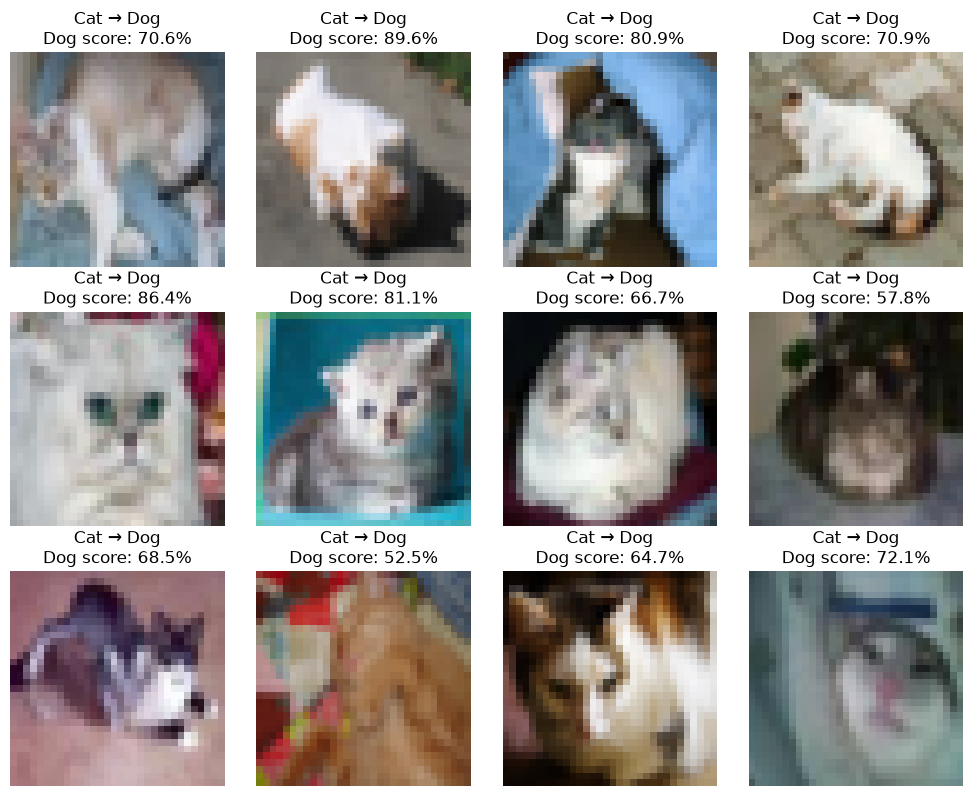

In [35]:
import matplotlib.pyplot as plt

model = deeper_model_native
model.eval()

classes = train_dataset.classes
cat_idx = classes.index("cat")
dog_idx = classes.index("dog")
mistakes = []

with torch.no_grad():
    for images, labels in val_loader:
        logits = model(images.to(device))
        probabilities = logits.softmax(dim=1)
        predictions = logits.argmax(dim=1).cpu()

        mask = (labels.cpu() == cat_idx) & (predictions == dog_idx)

        for i in mask.nonzero(as_tuple=True)[0].tolist():
            mistakes.append((
                images[i].cpu(),
                probabilities[i, dog_idx].item(),
            ))

        if len(mistakes) >= 12:
            break

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax in axes.flat:
    ax.axis("off")

for ax, (img, confidence) in zip(axes.flat, mistakes[:12]):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f"Cat → Dog\nDog score: {confidence:.1%}")

plt.tight_layout()
plt.show()